In [87]:
import pandas as pd
import numpy as np

from sklearn.datasets import make_regression

import plotly.express as px
import plotly.graph_objects as go

In [159]:
x,y = make_regression(n_samples = 200, n_features = 2, n_informative = 2, n_targets = 1)

In [160]:
x.shape, y.shape

((200, 2), (200,))

In [161]:
data = {
    'feature_1': x[:,0],
    'feature_2': x[:, 1],
    'target': y
}

df = pd.DataFrame(data)

df.head()

,feature_1,feature_2,target
0,-1.924960,-0.216431,-201.676259
1,-0.174947,0.171232,-1.845799
2,-1.152552,-0.761203,-175.288057
3,1.889345,0.384794,212.827762
4,-0.667054,1.006481,23.492564


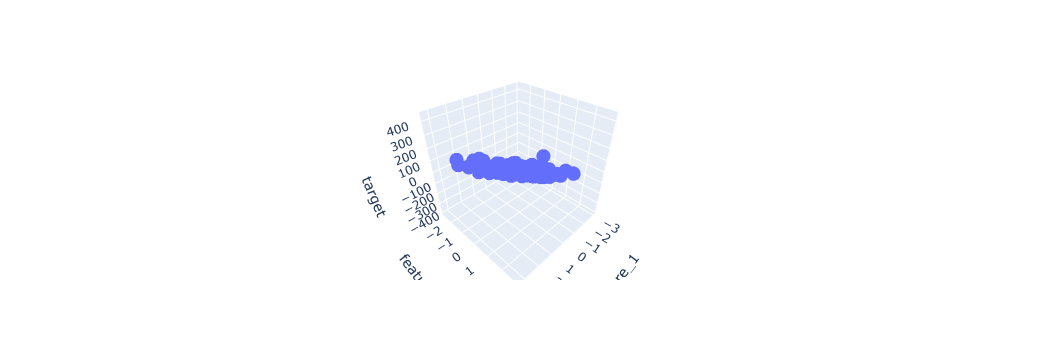

In [162]:
px.scatter_3d(df, x = 'feature_1', y = 'feature_2', z = 'target')

In [163]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [164]:
x = df.iloc[:, 0:2]
y = df.drop(x, axis = 'columns')

In [165]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

In [166]:
x_train

,feature_1,feature_2
108,-0.090434,0.345987
107,0.285329,-0.598443
189,1.863830,-1.836598
14,0.354148,0.855577
56,-2.980618,-1.271132
...,...,...
133,-0.047762,-1.513716
137,0.918110,0.536122
72,0.783388,-0.161539
140,-0.514639,-0.127699


In [167]:
x_train.shape

(160, 2)

In [168]:
lr = LinearRegression(n_jobs = -1)

lr.fit(x_train, y_train)

LinearRegression(n_jobs=-1)

In [169]:
print(lr.coef_)
print(lr.intercept_)

[[95.06108922 86.3438566 ]]
[5.32907052e-15]


In [170]:
lr.coef_

array([[95.06108922, 86.3438566 ]])

In [171]:
lr.intercept_

array([5.32907052e-15])

In [172]:
pred = lr.predict(x_test)

In [173]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [174]:
print(f'MeanSquareError: {mean_squared_error(y_test, pred)}')
print(f'MeanAbsoluteError: {mean_absolute_error(y_test, pred)}')
print(f'R2Score: {r2_score(y_test, pred)}')

# R2 score is 1 means both this columns, combined, is explaining 100% of target.

MeanSquareError: 2.7046108461454035e-27
MeanAbsoluteError: 4.329314684525798e-14
R2Score: 1.0


# Let's visualize the plane the model has created.

Don't try to understand the code, it is taken from chatgpt

C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning:

X does not have valid feature names, but LinearRegression was fitted with feature names



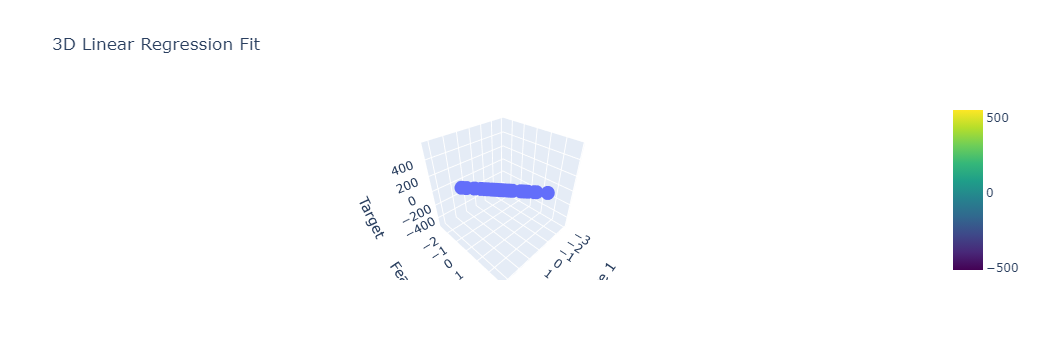

In [175]:
import numpy as np
import plotly.graph_objects as go
import plotly.express as px

# Step 1: Create a grid from x and y
x = np.linspace(x_train.iloc[:, 0].min(), x_train.iloc[:, 0].max(), 10)
y = np.linspace(x_train.iloc[:, 1].min(), x_train.iloc[:, 1].max(), 10)
xGrid, yGrid = np.meshgrid(x, y)

# Step 2: Flatten and stack the grid into (100, 2)
grid_points = np.vstack((xGrid.ravel(), yGrid.ravel())).T  # shape: (100, 2)

# Step 3: Predict z values for the grid
z_pred = lr.predict(grid_points).reshape(xGrid.shape)

# Step 4: Create 3D scatter plot with actual data
fig = px.scatter_3d(
    x=x_test.iloc[:, 0],
    y=x_test.iloc[:, 1],
    z=y_test.iloc[:, 0],
    labels={'x': 'Feature 1', 'y': 'Feature 2', 'z': 'Target'},
    title="3D Linear Regression Fit"
)

# Step 5: Add the regression surface
fig.add_trace(go.Surface(x=x, y=y, z=z_pred, colorscale='Viridis', opacity=0.6, name='Prediction Surface'))

# Show the plot
fig.show()


# Complete

# Next Session: 60 - Polynomial Regression.